In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.precision', 4)

IMAGES = Path('images')
IMAGES.mkdir(exist_ok=True)

def save(fig, name):
    """Сохраняет рисунок в images/<name>.png для вставки в отчёт."""
    fig.savefig(IMAGES / f'{name}.png', dpi=150, bbox_inches='tight')


In [2]:
COLS = ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation',
        'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']
TARGET = 'income'

def load(path):
    df = pd.read_csv(path, names=COLS, skipinitialspace=True, na_values='?', comment='|')
    df[TARGET] = df[TARGET].str.rstrip('.')
    return df.dropna().drop(columns=['fnlwgt', 'education']).reset_index(drop=True)

train_df = load('adult.data')
test_df = load('adult.test')
print(train_df.shape, test_df.shape)
train_df.head()

(30162, 13) (15060, 13)


,age,workclass,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
train_df[TARGET].value_counts()

income
<=50K    22654
>50K      7508
Name: count, dtype: int64

In [4]:
def entropy(c):
    n = c.sum(-1, keepdims=True)
    p = np.divide(c, n, out=np.zeros(c.shape), where=n > 0)
    return -(p * np.log2(np.where(p > 0, p, 1))).sum(-1)

def gini(c):
    n = c.sum(-1, keepdims=True)
    p = np.divide(c, n, out=np.zeros(c.shape), where=n > 0)
    return 1 - (p ** 2).sum(-1)

def weighted_impurity(f, children):
    n = children.sum(-1)
    return (n / n.sum(-1, keepdims=True) * f(children)).sum(-1)

def split_info(children):
    return entropy(children.sum(-1))


class Node:
    def __init__(self, counts, classes):
        self.counts = counts
        self.n = int(counts.sum())
        self.pred = classes[counts.argmax()]
        self.attr = self.threshold = None
        self.children = {}

    @property
    def is_leaf(self):
        return not self.children


class DecisionTree:
    CRITERIA = {'gain': 'Information gain', 'gain_ratio': 'Gain ratio', 'gini': 'Gini index'}

    def __init__(self, criterion='gain', max_depth=8, min_samples_split=50, min_gain=1e-3):
        assert criterion in self.CRITERIA
        self.criterion = criterion
        self.impurity = gini if criterion == 'gini' else entropy
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_gain = min_gain

    def fit(self, X, y):
        self.classes = np.unique(y)
        self.numeric = {c: pd.api.types.is_numeric_dtype(X[c]) for c in X.columns}
        self.cats = {c: X[c].astype('category').cat.categories for c in X.columns if not self.numeric[c]}
        cols = self._encode(X)
        yi = np.searchsorted(self.classes, np.asarray(y))
        self.root = self._build(cols, yi, np.arange(len(yi)), 0)
        return self

    def _encode(self, X):
        return {c: X[c].to_numpy(float) if self.numeric[c]
                else pd.Categorical(X[c], categories=self.cats[c]).codes for c in X.columns}

    def _counts(self, y):
        return np.bincount(y, minlength=len(self.classes)).astype(float)

    def _score(self, parent, children):
        gain = self.impurity(parent) - weighted_impurity(self.impurity, children)
        if self.criterion == 'gain_ratio':
            si = split_info(children)
            return gain, np.divide(gain, si, out=np.zeros_like(gain), where=si > 0)
        return gain, gain

    def _split_numeric(self, x, y, parent):
        order = np.argsort(x, kind='stable')
        xs, ys = x[order], y[order]
        cum = np.cumsum(np.eye(len(self.classes))[ys], axis=0)
        pos = np.nonzero(xs[1:] != xs[:-1])[0]
        if len(pos) == 0:
            return None
        left = cum[pos]
        children = np.stack([left, parent - left], axis=1)
        gain, score = self._score(parent, children)
        i = gain.argmax() if self.criterion == 'gain_ratio' else score.argmax()
        return gain[i], score[i], (xs[pos[i]] + xs[pos[i] + 1]) / 2

    def _split_categorical(self, x, y, parent):
        k = len(self.classes)
        children = np.bincount(x * k + y, minlength=(x.max() + 1) * k).reshape(-1, k).astype(float)
        children = children[children.sum(1) > 0]
        if len(children) < 2:
            return None
        gain, score = self._score(parent, children[None])
        return gain[0], score[0], None

    def _build(self, cols, y, idx, depth):
        parent = self._counts(y[idx])
        node = Node(parent, self.classes)
        if depth >= self.max_depth or len(idx) < self.min_samples_split or (parent > 0).sum() < 2:
            return node
        cands = []
        for c, x in cols.items():
            split = (self._split_numeric if self.numeric[c] else self._split_categorical)(x[idx], y[idx], parent)
            if split is not None and split[0] > self.min_gain:
                cands.append((c, *split))
        if not cands:
            return node
        if self.criterion == 'gain_ratio':
            avg = np.mean([g for _, g, _, _ in cands])
            cands = [s for s in cands if s[1] >= avg - 1e-12]
        attr, _, _, thr = max(cands, key=lambda s: s[2])
        node.attr, node.threshold = attr, thr
        x = cols[attr][idx]
        if thr is not None:
            parts = {'<= %g' % thr: idx[x <= thr], '> %g' % thr: idx[x > thr]}
        else:
            parts = {self.cats[attr][v]: idx[x == v] for v in np.unique(x)}
        node.children = {k: self._build(cols, y, v, depth + 1) for k, v in parts.items()}
        return node

    def predict(self, X):
        cols = self._encode(X)
        out = np.empty(len(X), dtype=self.classes.dtype)
        self._predict(self.root, cols, np.arange(len(X)), out)
        return out

    def _predict(self, node, cols, idx, out):
        if node.is_leaf or len(idx) == 0:
            out[idx] = node.pred
            return
        x = cols[node.attr][idx]
        if node.threshold is not None:
            masks = [x <= node.threshold, x > node.threshold]
        else:
            masks = [x == self.cats[node.attr].get_loc(k) for k in node.children]
        covered = np.zeros(len(idx), bool)
        for child, m in zip(node.children.values(), masks):
            self._predict(child, cols, idx[m], out)
            covered |= m
        out[idx[~covered]] = node.pred

    def stats(self):
        def walk(n, d):
            if n.is_leaf:
                return 1, 1, d
            r = [walk(c, d + 1) for c in n.children.values()]
            return 1 + sum(a for a, _, _ in r), sum(b for _, b, _ in r), max(c for _, _, c in r)
        nodes, leaves, depth = walk(self.root, 0)
        return {'nodes': nodes, 'leaves': leaves, 'depth': depth}

In [5]:
def metrics(y_true, y_pred, positive='>50K'):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = np.sum((y_pred == positive) & (y_true == positive))
    fp = np.sum((y_pred == positive) & (y_true != positive))
    fn = np.sum((y_pred != positive) & (y_true == positive))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {'accuracy': np.mean(y_true == y_pred), 'precision': precision, 'recall': recall, 'f1': f1}

In [6]:
def classify(data, criterion, train_frac=1.0, test=None, target=TARGET, seed=42, **tree_params):
    data = data.sample(frac=1, random_state=seed).reset_index(drop=True)
    n_train = int(round(len(data) * train_frac))
    train = data.iloc[:n_train]
    if test is None:
        test = data.iloc[n_train:] if train_frac < 1 else train
    tree = DecisionTree(criterion, **tree_params).fit(train.drop(columns=target), train[target])
    res = metrics(test[target], tree.predict(test.drop(columns=target)))
    return tree, res

In [ ]:
COLORS = {'<=50K': '#9ecae1', '>50K': '#fdae6b'}

def plot_tree(tree, max_depth=3, max_children=4, title=None, save_as=None):
    pos, edges = {}, []
    leaf_x = [0]

    def visible_children(node):
        kids = sorted(node.children.items(), key=lambda kv: -kv[1].n)
        if len(kids) <= max_children:
            return list(node.children.items())
        rest = kids[max_children - 1:]
        other = Node(sum(c.counts for _, c in rest), tree.classes)
        other.collapsed = True
        return kids[:max_children - 1] + [(f'ещё {len(rest)} знач.', other)]

    def layout(node, depth):
        kids = visible_children(node) if depth < max_depth else []
        if not kids:
            pos[id(node)] = (leaf_x[0], -depth, node)
            leaf_x[0] += 1
            return leaf_x[0] - 1
        xs = [layout(c, depth + 1) for _, c in kids]
        x = (xs[0] + xs[-1]) / 2
        pos[id(node)] = (x, -depth, node)
        edges.extend((id(node), id(c), str(lbl)) for lbl, c in kids)
        return x

    layout(tree.root, 0)
    fig, ax = plt.subplots(figsize=(max(12, leaf_x[0] * 1.35), 2.6 * (max_depth + 1)))
    for a, b, lbl in edges:
        (x1, y1, _), (x2, y2, _) = pos[a][:3], pos[b][:3]
        ax.plot([x1, x2], [y1, y2], color='gray', lw=0.8, zorder=1)
        ax.text(x1 + (x2 - x1) * 0.6, y1 + (y2 - y1) * 0.6, lbl, fontsize=7, ha='center',
                va='center', color='dimgray',
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none'))
    for x, y, node in pos.values():
        share = node.counts.max() / node.n
        if getattr(node, 'collapsed', False):
            head = '(свёрнуто)'
        else:
            head = node.attr if not node.is_leaf and y > -max_depth else ('...' if not node.is_leaf else 'leaf')
        txt = f'{head}\n{node.pred} ({share:.0%})\nn={node.n}'
        ax.text(x, y, txt, fontsize=7.5, ha='center', va='center', zorder=2,
                bbox=dict(boxstyle='round,pad=0.35', fc=COLORS.get(node.pred, 'white'), ec='black', lw=0.6))
    ax.set_xlim(-1, leaf_x[0])
    ax.set_ylim(-max_depth - 0.5, 0.5)
    ax.axis('off')
    ax.set_title(title or f'Дерево решений ({DecisionTree.CRITERIA[tree.criterion]})')
    plt.tight_layout()
    if save_as:
        save(fig, save_as)
    plt.show()

In [8]:
PARAMS = dict(max_depth=8, min_samples_split=50, min_gain=1e-3)
CRITERIA = list(DecisionTree.CRITERIA)

trees, rows = {}, []
for crit in CRITERIA:
    tree, res_train = classify(train_df, crit, 1.0, **PARAMS)
    res_test = metrics(test_df[TARGET], tree.predict(test_df.drop(columns=TARGET)))
    trees[crit] = tree
    rows.append({'criterion': DecisionTree.CRITERIA[crit], **tree.stats(),
                 **{f'train_{k}': v for k, v in res_train.items()},
                 **{f'test_{k}': v for k, v in res_test.items()}})
pd.DataFrame(rows).set_index('criterion')

,nodes,leaves,depth,train_accuracy,train_precision,train_recall,train_f1,test_accuracy,test_precision,test_recall,test_f1
criterion,,,,,,,,,,,
Information gain,1599,1229,8,0.8681,0.7926,0.6368,0.7062,0.8449,0.7286,0.5876,0.6505
Gain ratio,705,566,8,0.8614,0.7766,0.6221,0.6908,0.8544,0.7502,0.6105,0.6732
Gini index,1411,1099,8,0.8701,0.7916,0.6488,0.7131,0.8464,0.7254,0.6032,0.6587


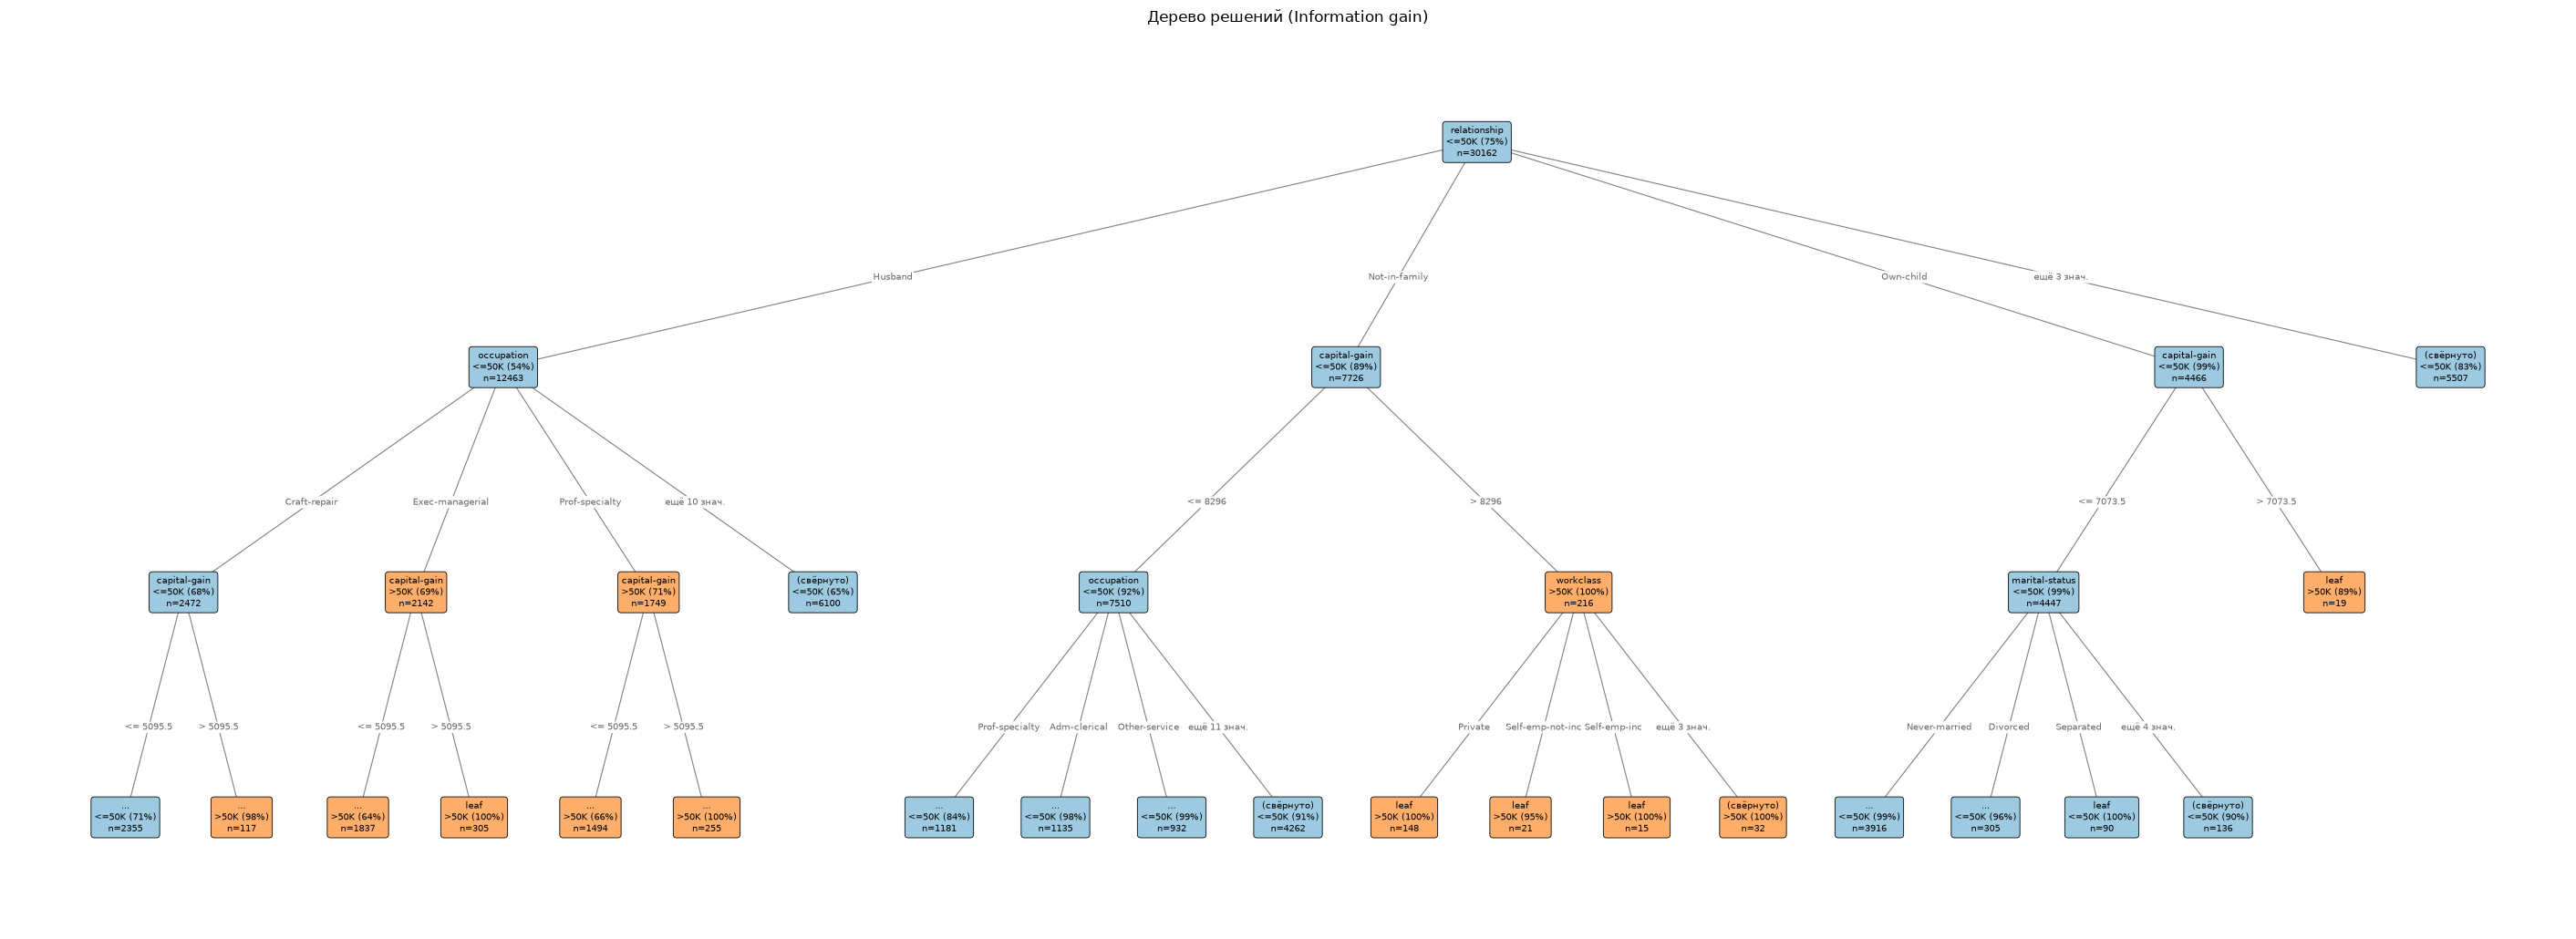

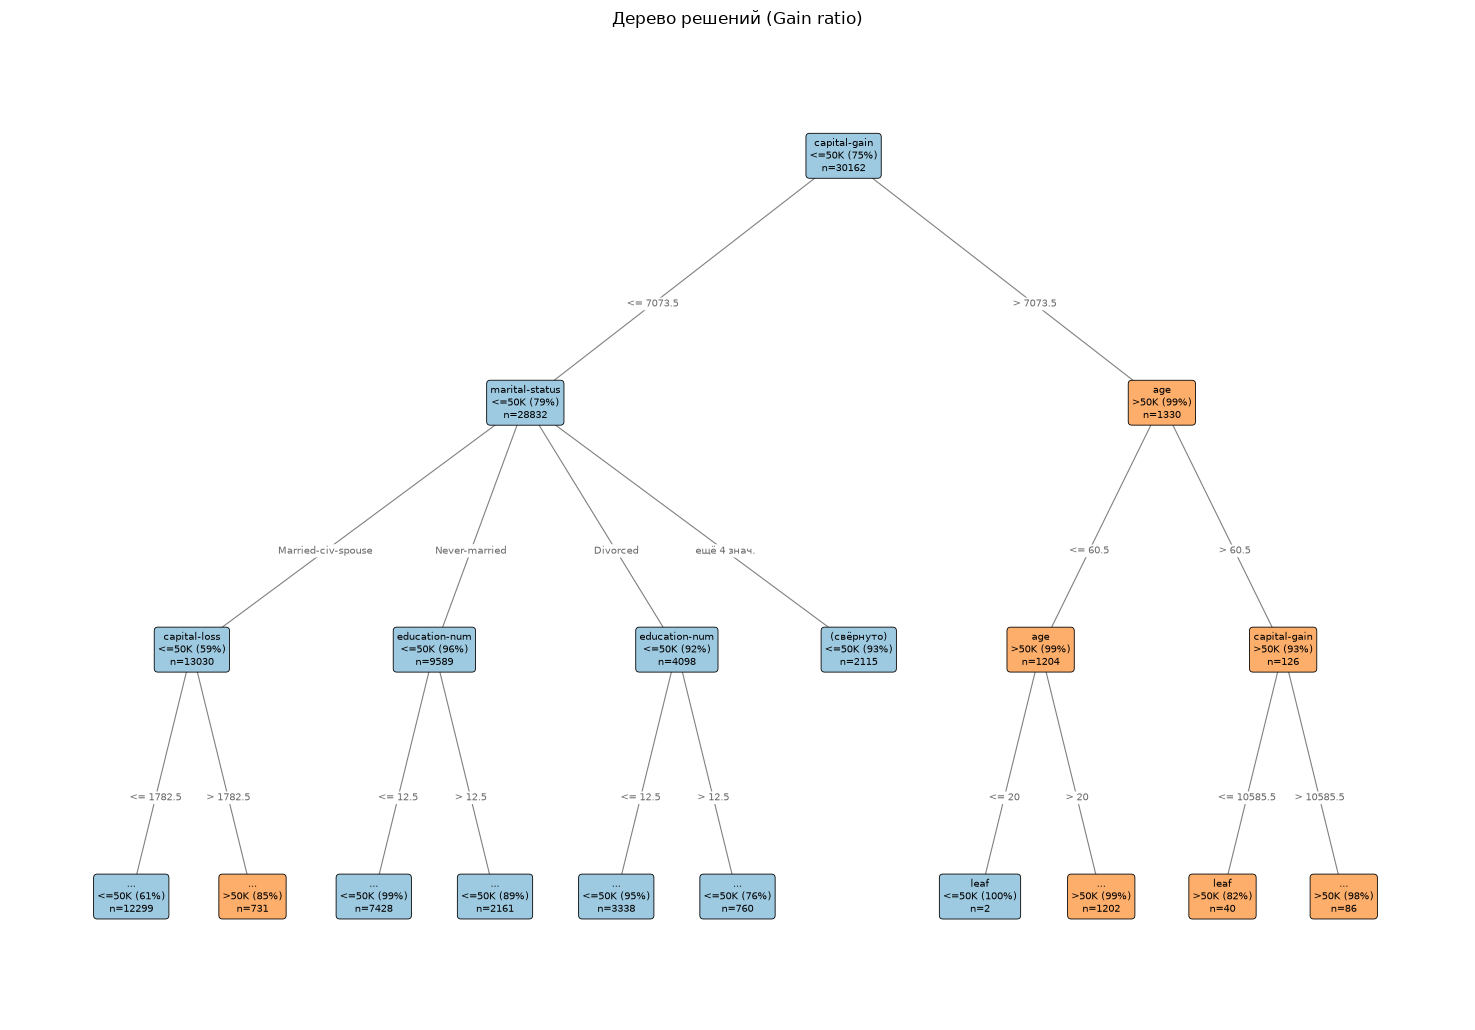

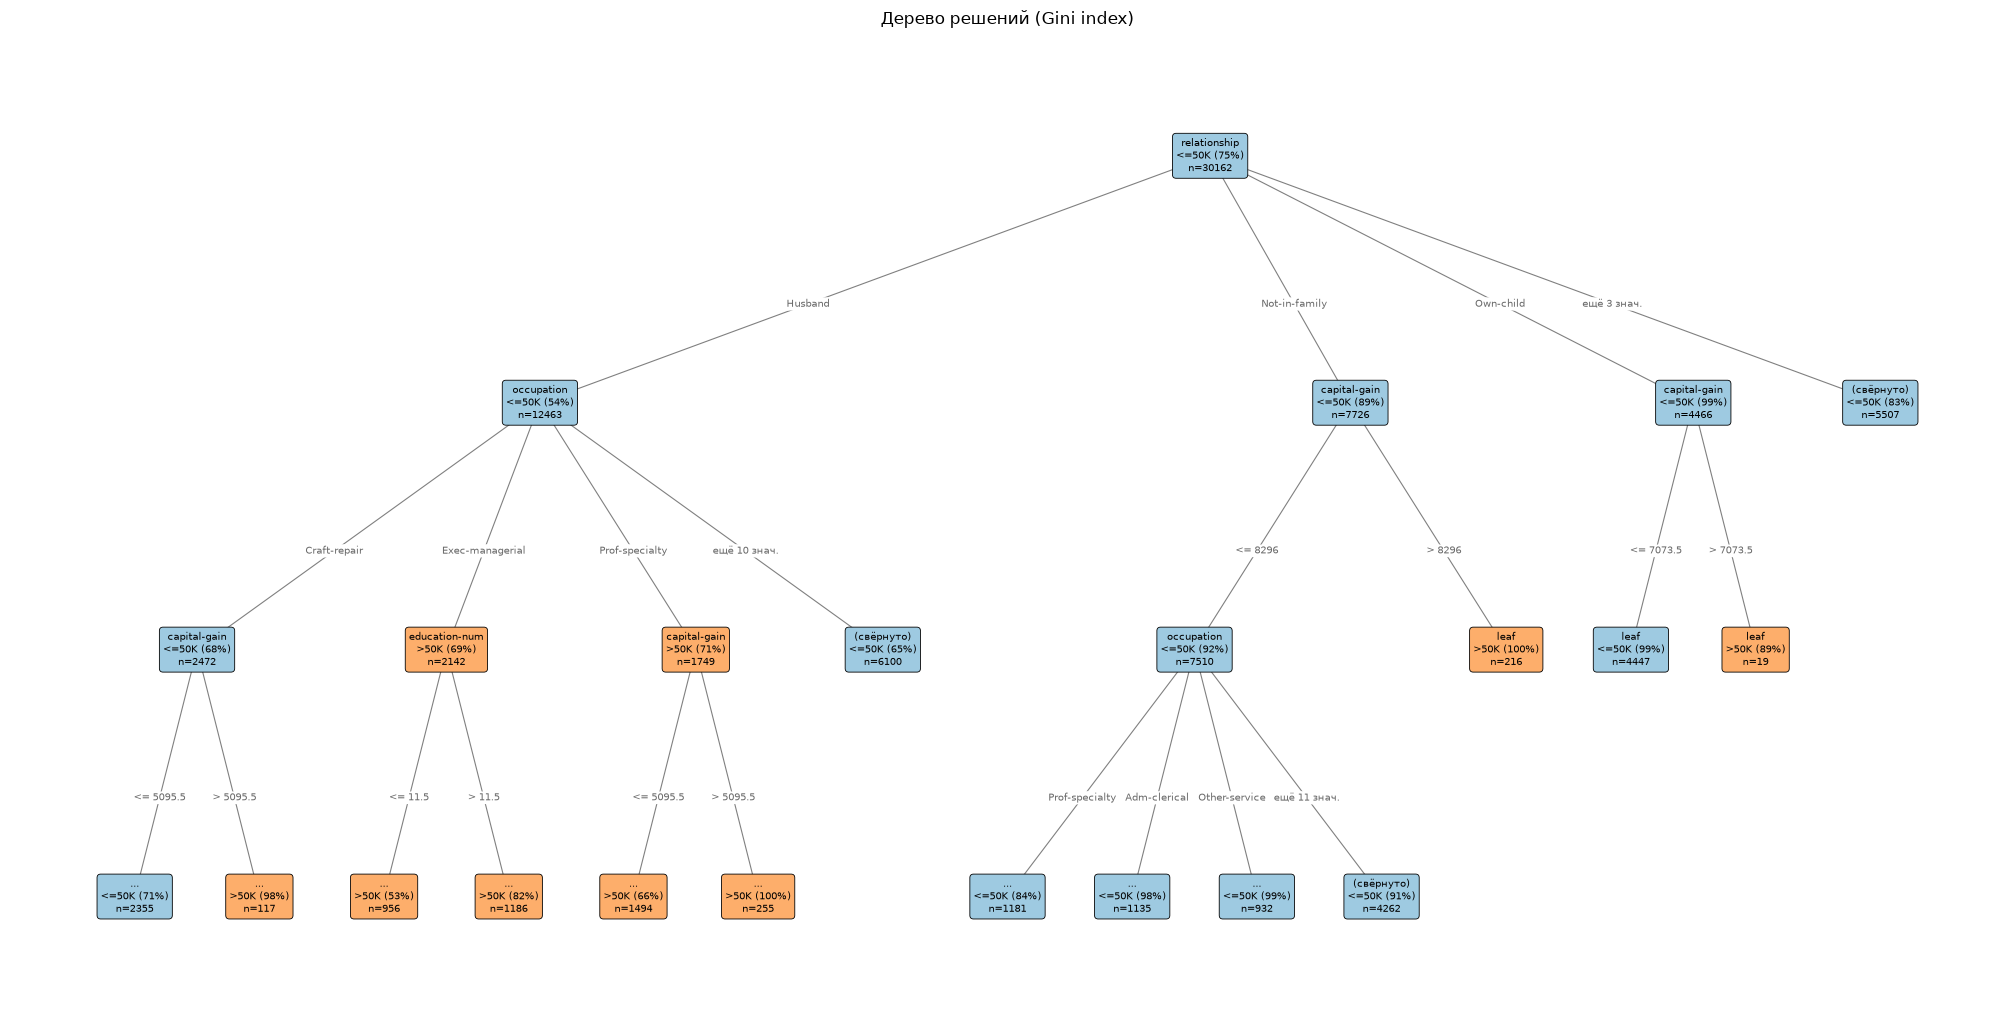

In [9]:
for crit in CRITERIA:
    plot_tree(trees[crit], max_depth=3, save_as=f'tree_{crit}')


In [10]:
full_df = pd.concat([train_df, test_df], ignore_index=True)
FRACS = [0.6, 0.7, 0.8, 0.9]

rows = []
for crit in CRITERIA:
    for frac in FRACS:
        _, res = classify(full_df, crit, frac, **PARAMS)
        rows.append({'criterion': DecisionTree.CRITERIA[crit], 'split': f'{frac:.0%}:{1 - frac:.0%}', **res})
results = pd.DataFrame(rows)
results.pivot(index='split', columns='criterion')

accuracy                              precision             \
criterion Gain ratio Gini index Information gain Gain ratio Gini index   
split                                                                    
60%:40%       0.8507     0.8491           0.8473     0.7997     0.7275   
70%:30%       0.8479     0.8491           0.8478     0.7453     0.7558   
80%:20%       0.8501     0.8508           0.8511     0.7826     0.7495   
90%:10%       0.8481     0.8490           0.8518     0.7848     0.7527   

                               recall                                     f1  \
criterion Information gain Gain ratio Gini index Information gain Gain ratio   
split                                                                          
60%:40%             0.7218     0.5232     0.6162           0.6150     0.6326   
70%:30%             0.7360     0.5878     0.5786           0.6024     0.6573   
80%:20%             0.7500     0.5542     0.6059           0.6064     0.6489   
90%:10%             0.7508     0.5511     0.6009           0.6210     0.6475   

                                       
criterion Gini index Information gain  
split                                  
60%:40%       0.6672           0.6642  
70%:30%       0.6554           0.6625  
80%:20%       0.6701           0.6706  
90%:10%       0.6683           0.6797

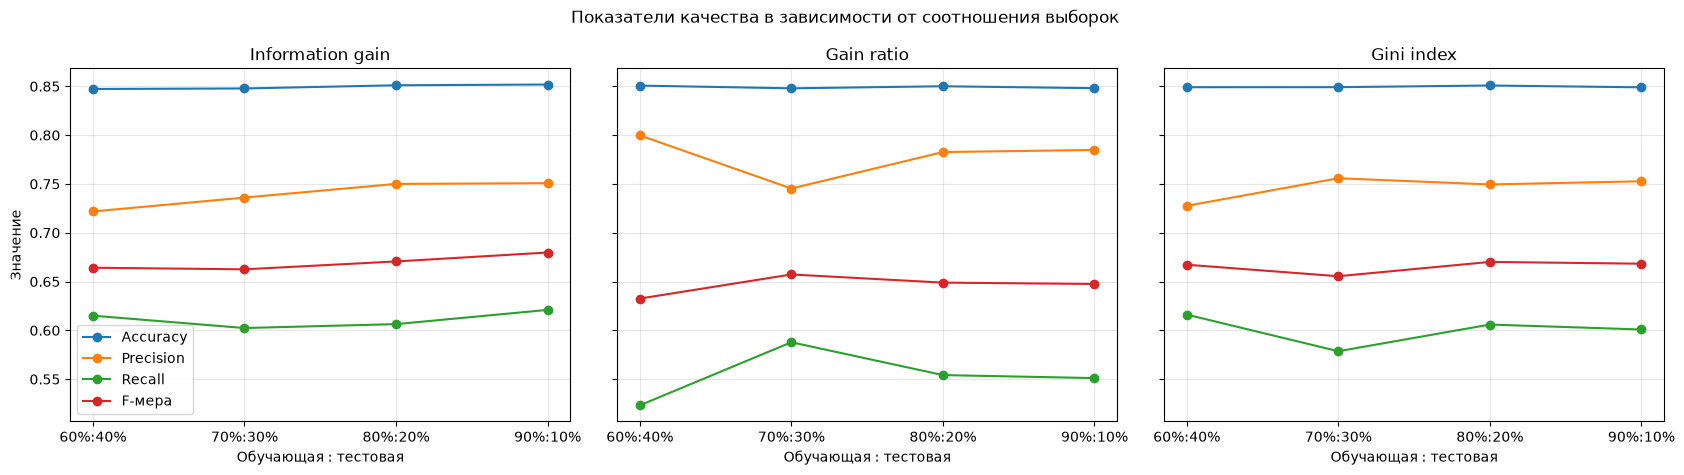

In [11]:
METRICS = {'accuracy': 'Accuracy', 'precision': 'Precision', 'recall': 'Recall', 'f1': 'F-мера'}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for ax, (crit, grp) in zip(axes, results.groupby('criterion', sort=False)):
    for m, name in METRICS.items():
        ax.plot(grp['split'], grp[m], marker='o', label=name)
    ax.set_title(crit)
    ax.set_xlabel('Обучающая : тестовая')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Значение')
axes[0].legend()
plt.suptitle('Показатели качества в зависимости от соотношения выборок')
plt.tight_layout()
save(fig, 'metrics_by_criterion')
plt.show()

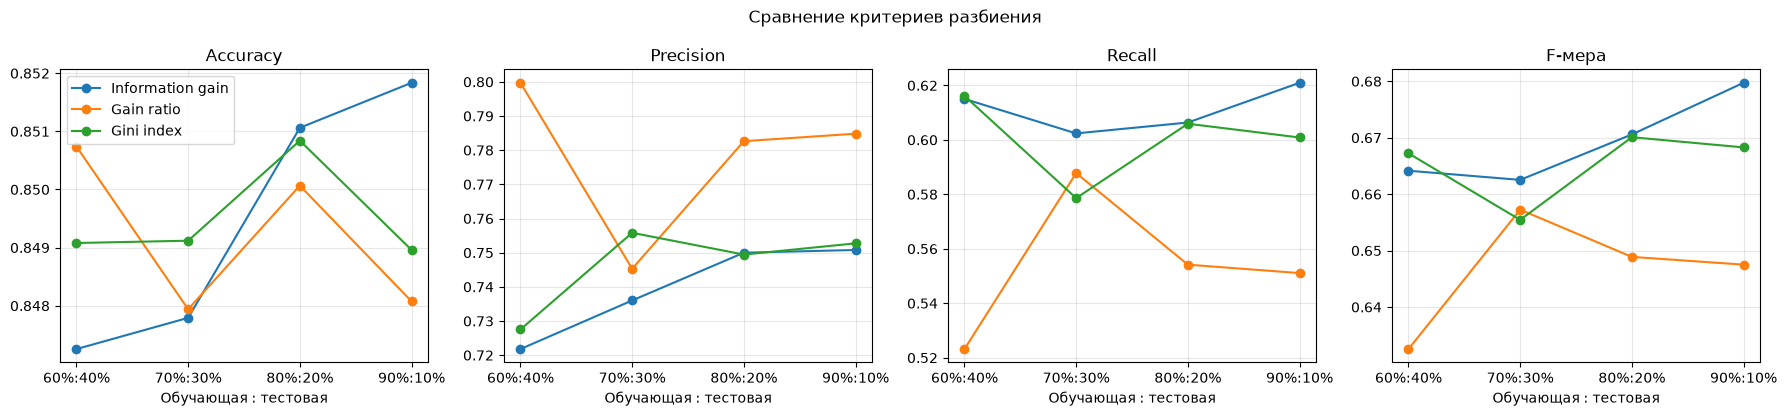

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (m, name) in zip(axes, METRICS.items()):
    for crit, grp in results.groupby('criterion', sort=False):
        ax.plot(grp['split'], grp[m], marker='o', label=crit)
    ax.set_title(name)
    ax.set_xlabel('Обучающая : тестовая')
    ax.grid(alpha=0.3)
axes[0].legend()
plt.suptitle('Сравнение критериев разбиения')
plt.tight_layout()
save(fig, 'criteria_comparison')
plt.show()